# Forecast contracts

A point mean, a marginal interval, and a joint future path are different objects. Make the horizon, target, and sample axes visible.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp contracts

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `contracts`

### Imports and configuration

In [3]:
#| export contracts
from __future__ import annotations
from timegym._internal import positive_int, nonnegative_int, _real_array, _has_complex_values

from dataclasses import dataclass, field
from typing import Any, Callable

import numpy as np
import pandas as pd
from scipy.stats import norm

DEFAULT_LEVELS = (0.1, 0.5, 0.9)
MANIFEST_SCHEMA_VERSION = 1


### ForecastTask — The information a forecaster may observe at a single forecast origin.

In [4]:
#| export contracts
def _index_value_problem(index: pd.Index) -> str | None:
    """Identify missing or infinite labels without coercing time indexes."""
    if isinstance(index, pd.MultiIndex):
        if any(np.any(codes < 0) for codes in index.codes):
            return "missing"
        for level in index.levels:
            problem = _index_value_problem(level)
            if problem is not None:
                return problem
    else:
        if index.hasnans:
            return "missing"
        for value in index:
            # Object indexes may contain tuples even when they are not a
            # MultiIndex. Inspect each component, including nested tuples.
            if isinstance(value, tuple):
                problem = _index_value_problem(pd.Index(value, tupleize_cols=False))
                if problem is not None:
                    return problem
            elif isinstance(value, (float, complex, np.floating, np.complexfloating)) and not np.isfinite(value):
                return "nonfinite"
    return None


def _target_labels(values, name="target names") -> tuple:
    """Normalize unique hashable labels, rejecting scalar strings and missing names."""
    if isinstance(values, (str, bytes)):
        raise ValueError(f"{name} must be a sequence of unique, nonmissing labels")
    try:
        names = tuple(values)
        if not names or len(set(names)) != len(names):
            raise ValueError
        index = pd.Index(names, tupleize_cols=False)
        if _index_value_problem(index) is not None:
            raise ValueError
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be a sequence of unique, nonmissing, finite, hashable labels") from None
    return names

### How far are the dates off?

A forecast for the wrong dates fails the date check before it is scored. When
the labels are the requested ones moved by whole steps, say how many, so a
report can read "dates shifted 1 step early" instead of only "mismatch".

In [5]:
#| export contracts
def _index_shift(index, future_index):
    """Return ``k`` when ``index`` is the requested ``future_index`` moved ``k`` steps.

    Negative ``k`` means the labels start early (``-1``: at the last observed
    step), positive means late. Returns ``None`` when the labels are not a
    whole-step shift of the requested ones, for example a truncated horizon.
    Steps come from the requested index: its frequency for time indexes, its
    constant spacing for numeric ones.
    """
    if not isinstance(index, pd.Index) or len(index) != len(future_index) or len(index) == 0:
        return None
    if index.equals(future_index):
        return 0
    if isinstance(future_index, (pd.DatetimeIndex, pd.TimedeltaIndex, pd.PeriodIndex)):
        frequency = future_index.freq
        if frequency is None and len(future_index) >= 3:
            frequency = pd.infer_freq(future_index)
        if frequency is None:
            return None

        def moved(k):
            return future_index.shift(k, freq=frequency) if not isinstance(future_index, pd.PeriodIndex) else future_index + k
    elif pd.api.types.is_numeric_dtype(future_index.dtype) and len(future_index) >= 2:
        steps = np.diff(future_index.to_numpy())
        if not np.all(steps == steps[0]) or steps[0] == 0:
            return None

        def moved(k):
            return future_index + k * steps[0]
    else:
        return None
    for distance in range(1, 4 * len(future_index) + 1):
        for k in (-distance, distance):
            try:
                if index.equals(moved(k)):
                    return k
            except (TypeError, ValueError, OverflowError):
                return None
    return None


def _describe_shift(k):
    """Say in words how far forecast dates moved from the requested ones."""
    steps = f"{abs(k)} step{'s' if abs(k) != 1 else ''}"
    return f"shifted {steps} {'early' if k < 0 else 'late'}"

In [6]:
#| export contracts
@dataclass
class ForecastTask:
    """The information a forecaster may observe at a single forecast origin."""

    context: pd.DataFrame
    future_index: pd.Index

    def __post_init__(self) -> None:
        if not isinstance(self.context, pd.DataFrame):
            raise TypeError("context must be a pandas DataFrame")
        if self.context.empty or len(self.context.columns) == 0:
            raise ValueError("context must contain at least one row and target")
        _target_labels(self.context.columns, "context target names")
        for name, index in (("context", self.context.index), ("future", self.future_index)):
            if not isinstance(index, pd.Index):
                raise TypeError(f"{name} index must be a pandas Index")
            problem = _index_value_problem(index)
            if problem is not None:
                raise ValueError(f"{name} index must not contain {problem} labels")
            if len(index) == 0 or not index.is_unique or not index.is_monotonic_increasing:
                raise ValueError(f"{name} index must be nonempty, unique, and increasing")
        try:
            values = _real_array(self.context.to_numpy(), "context")
        except (TypeError, ValueError) as exc:
            raise ValueError("context values must be real numeric values") from exc
        if not np.isfinite(values).all():
            raise ValueError("context values must be finite")
        try:
            follows_context = self.future_index[0] > self.context.index[-1]
        except TypeError as exc:
            raise ValueError("context and future indexes must be comparable") from exc
        if not follows_context:
            raise ValueError("future index must begin after the context ends")

    @property
    def target_names(self) -> tuple:
        """The context's target column names, in order."""
        return tuple(self.context.columns)

### Forecast — A model output, including malformed outputs that need diagnosis.

In [7]:
#| export contracts
@dataclass
class Forecast:
    """A model output, including malformed outputs that need diagnosis.

    Construction intentionally does not validate or repair data. Call
    ``validate`` to obtain stable diagnostic codes before scoring it.
    A point forecast denotes a predictive mean, not an arbitrary quantile.
    """

    index: pd.Index
    point: np.ndarray | None = None
    quantiles: np.ndarray | None = None
    levels: tuple = ()
    samples: np.ndarray | None = None
    target_names: tuple = ("y",)

    def validate(self, task: ForecastTask | None = None) -> list[dict[str, str]]:
        """Return one ``{"code", "message"}`` finding per contract violation.

        An empty list means the output meets its contract. With a ``task``, the
        index and target names must also match the task's future index and
        targets. Each code is reported as the diagnostic ``contract_<code>``.
        """
        findings: list[dict[str, str]] = []

        def add(code: str, message: str) -> None:
            findings.append({"code": code, "message": message})

        if not isinstance(self.index, pd.Index):
            add("index_type", "Forecast index must be a pandas Index.")
            horizon = len(task.future_index) if task is not None else None
        else:
            horizon = len(self.index)
            problem = _index_value_problem(self.index)
            if problem is not None:
                add("index_" + problem, f"Forecast index contains {problem} labels.")
            if horizon == 0:
                add("index_empty", "Forecast index must not be empty.")
            if not self.index.is_unique:
                add("index_duplicate", "Forecast index contains duplicate labels.")
            if not self.index.is_monotonic_increasing:
                add("index_order", "Forecast index is not increasing.")
            if task is not None and not self.index.equals(task.future_index):
                add("index_mismatch", "Forecast index does not match the requested future index.")
        try:
            names = _target_labels(self.target_names)
        except (TypeError, ValueError):
            names = task.target_names if task is not None else ()
            add("target_names", "Forecast target names must be a sequence of unique, nonmissing, finite, hashable labels.")
        if task is not None and names != task.target_names:
            add("target_mismatch", "Forecast targets or their order do not match the task.")
        dimensions = len(names)

        try:
            levels = _real_array(self.levels, "levels")
        except (TypeError, ValueError):
            levels = np.array([np.nan])
        valid_levels = (
            levels.ndim == 1
            and np.isfinite(levels).all()
            and ((levels > 0) & (levels < 1)).all()
        )
        if not valid_levels:
            add("invalid_levels", "Quantile levels must be finite real numbers strictly between zero and one.")
        elif len(levels):
            if len(np.unique(levels)) != len(levels):
                add("duplicate_levels", "Quantile levels contain duplicates.")
            if np.any(np.diff(levels) < 0):
                add("nonmonotonic_levels", "Quantile levels must be in increasing order.")
        if self.quantiles is not None and levels.size == 0:
            add("invalid_levels", "Quantile predictions require explicit probability levels.")
        if self.quantiles is None and levels.size != 0:
            add("missing_quantiles", "Quantile levels were supplied without quantile predictions.")

        if self.point is None and self.quantiles is None and self.samples is None:
            add("missing_prediction", "Supply point predictions, quantiles, or predictive samples.")
        for label, raw in (("point", self.point), ("quantiles", self.quantiles), ("samples", self.samples)):
            if raw is None:
                continue
            shape_code = {"point": "point_shape", "quantiles": "quantile_shape", "samples": "sample_shape"}[label]
            try:
                values = np.asarray(raw)
                if _has_complex_values(values):
                    add(f"nonreal_{label}", f"Forecast {label} must contain real-valued numbers.")
                    continue
                values = np.asarray(values, dtype=float)
            except (TypeError, ValueError):
                add(f"nonfinite_{label}", f"Forecast {label} must contain finite numeric values.")
                continue
            if label == "point":
                shape_ok = values.ndim == 2 and values.shape == (horizon, dimensions)
                expected = "(horizon, targets)"
            elif label == "quantiles":
                shape_ok = values.ndim == 3 and values.shape == (horizon, dimensions, levels.size)
                expected = "(horizon, targets, levels)"
            else:
                shape_ok = values.ndim == 3 and values.shape[0] > 0 and values.shape[1:] == (horizon, dimensions)
                expected = "(samples > 0, horizon, targets)"
            if not shape_ok:
                add(shape_code, f"Forecast {label} has shape {values.shape}; expected {expected}.")
            finite_values = np.isfinite(values).all()
            if not finite_values:
                add(f"nonfinite_{label}", f"Forecast {label} contains nonfinite values.")
            if label == "quantiles" and shape_ok and finite_values and valid_levels and np.all(np.diff(levels) > 0):
                if np.any(values[..., 1:] < values[..., :-1]):
                    add("quantile_crossing", "Predicted quantiles decrease as the probability level increases.")
        return findings

    def mean(self) -> np.ndarray:
        """Return the reported mean, or an empirical mean of predictive samples."""
        if self.point is not None:
            return _real_array(self.point, "point")
        if self.samples is not None:
            return _real_array(self.samples, "samples").mean(axis=0)
        raise ValueError("A predictive mean cannot be inferred from marginal quantiles alone")

### Reference — A Gaussian conditional law given observed history and known parameters.

In [8]:
#| export contracts
@dataclass
class Reference:
    """A Gaussian conditional law given observed history and known parameters.

    This is an analytical diagnostic reference. Knowing generator parameters
    is an information advantage over an estimated forecasting model and must
    not be interpreted as attainable real-world performance.
    """

    mean: np.ndarray
    variance: np.ndarray
    covariance: np.ndarray
    index: pd.Index
    target_names: tuple = ("y",)
    kind: str = "analytic_conditional"
    functional: str = "mean"
    conditioning: dict[str, Any] = field(default_factory=dict)

    def __post_init__(self) -> None:
        self.validate()

    def validate(self) -> None:
        """Check current moments and labels using the construction tolerances."""
        self.mean = _real_array(self.mean, "Reference mean")
        self.variance = _real_array(self.variance, "Reference variance")
        self.covariance = _real_array(self.covariance, "Reference covariance")
        self.target_names = _target_labels(self.target_names, "Reference target names")
        if not isinstance(self.index, pd.Index) or len(self.index) == 0:
            raise ValueError("Reference index must be a nonempty pandas Index")
        problem = _index_value_problem(self.index)
        if problem is not None:
            raise ValueError(f"Reference index must not contain {problem} labels")
        if not self.index.is_unique or not self.index.is_monotonic_increasing:
            raise ValueError("Reference index must be unique and increasing")
        shape = (len(self.index), len(self.target_names))
        size = shape[0] * shape[1]
        if self.mean.shape != shape or self.variance.shape != shape:
            raise ValueError("Reference mean and variance must have shape (horizon, targets)")
        if self.covariance.shape != (size, size):
            raise ValueError("Reference covariance must have shape (horizon * targets, horizon * targets)")
        if not all(np.isfinite(a).all() for a in (self.mean, self.variance, self.covariance)):
            raise ValueError("Reference parameters must be finite")
        if np.any(self.variance < 0):
            raise ValueError("Reference variance must be nonnegative")
        if not np.allclose(self.covariance, self.covariance.T, rtol=1e-10, atol=1e-12):
            raise ValueError("Reference covariance must be symmetric")
        scale = max(1.0, float(np.max(np.abs(self.covariance))))
        if np.linalg.eigvalsh(self.covariance).min() < -1e-10 * scale:
            raise ValueError("Reference covariance must be positive semidefinite")
        if not np.allclose(np.diag(self.covariance).reshape(shape), self.variance):
            raise ValueError("Reference variance must agree with the covariance diagonal")

    @classmethod
    def from_function(
        cls,
        mean_function: Callable[[pd.Index], np.ndarray | pd.DataFrame],
        index: pd.Index,
        *,
        covariance: np.ndarray,
        target_names: tuple = ("y",),
        conditioning: dict[str, Any] | None = None,
    ) -> Reference:
        """Evaluate a user-supplied mean under an explicitly Gaussian noise law.

        ``mean_function(index)`` returns ``H,D`` values in target order, or a
        DataFrame with exactly matching labels. Covariance uses flattened
        horizon-major, target-minor order. It is required: knowing a mean does
        not imply zero noise or identify a conditional distribution.

        The function is evaluated once and is not retained or serialized.
        Supply only evaluator-known truth, not a fitted estimate presented as
        ground truth. For non-Gaussian laws, use ``SimulationReference``.
        """
        from copy import deepcopy

        if not callable(mean_function):
            raise TypeError("mean_function must be callable as mean_function(index)")
        if not isinstance(index, pd.Index) or len(index) == 0:
            raise ValueError("Reference index must be a nonempty pandas Index")
        names = _target_labels(target_names, "Reference target names")
        if conditioning is not None and not isinstance(conditioning, dict):
            raise TypeError("conditioning must be a dictionary or None")
        covariance = _real_array(covariance, "Reference covariance").copy()
        shape = (len(index), len(names))
        size = shape[0] * shape[1]
        if covariance.shape != (size, size):
            raise ValueError(
                "Reference covariance must have shape (horizon * targets, horizon * targets)"
            )
        mean = mean_function(index.copy(deep=True))
        if isinstance(mean, pd.DataFrame):
            if not mean.index.equals(index) or tuple(mean.columns) != names:
                raise ValueError(
                    "mean_function output index and target order must match the reference"
                )
        return cls(
            mean=_real_array(mean, "Reference mean").copy(),
            variance=np.diag(covariance).reshape(shape).copy(),
            covariance=covariance,
            index=index.copy(deep=True),
            target_names=names,
            kind="user_supplied_gaussian",
            conditioning=deepcopy(conditioning) if conditioning is not None else {},
        )

    def sample(self, n_samples: int, seed: int = 0) -> np.ndarray:
        """Draw joint futures with an isolated random generator, shape ``S,H,D``."""
        n_samples = positive_int(n_samples, 'n_samples')
        rng = np.random.default_rng(seed)
        eigenvalues, eigenvectors = np.linalg.eigh(self.covariance)
        factor = eigenvectors * np.sqrt(np.maximum(eigenvalues, 0.0))
        noise = rng.standard_normal((n_samples, self.mean.size)) @ factor.T
        return (noise + self.mean.reshape(-1)).reshape(n_samples, *self.mean.shape)

    def quantile(self, levels: tuple = DEFAULT_LEVELS) -> np.ndarray:
        """Return analytical marginal Gaussian quantiles, shape ``H,D,Q``."""
        probabilities = _real_array(levels, "levels")
        if probabilities.ndim != 1 or probabilities.size == 0:
            raise ValueError("levels must be a nonempty one-dimensional sequence")
        if not np.isfinite(probabilities).all() or np.any((probabilities <= 0) | (probabilities >= 1)):
            raise ValueError("levels must be finite and strictly between zero and one")
        if np.any(np.diff(probabilities) <= 0):
            raise ValueError("levels must be unique and increasing")
        return self.mean[..., None] + np.sqrt(self.variance)[..., None] * norm.ppf(probabilities)

    def forecast(self, n_samples: int = 256, seed: int = 0, levels: tuple = DEFAULT_LEVELS) -> Forecast:
        """Construct a correctly aligned forecast from this reference law."""
        return Forecast(
            index=self.index.copy(),
            point=self.mean.copy(),
            quantiles=self.quantile(levels),
            levels=tuple(levels),
            samples=self.sample(n_samples, seed),
            target_names=self.target_names,
        )

### SimulationReference — preserve non-Gaussian conditional laws

Jumps and hidden regimes can create non-Gaussian futures even when their conditional moments are known. An explicit simulator preserves that law. Marginal quantiles are reproducible Monte Carlo estimates; approximate simulators cannot supply an exact diagnostic null.


Multivariate CCC-GARCH retains analytic means and marginal variances, but its general cross-series covariance uses a separate reproducible Monte Carlo calculation. `moments_kind`, `moment_samples`, and `moment_seed` disclose this. Exact conditional sampling is a separate capability: rank calibration uses the same fixed covariance target for every independent null ensemble.

In [9]:
#| export contracts
@dataclass
class SimulationReference(Reference):
    """Conditional moments with an explicit joint future simulator.

    Unlike ``Reference``, this class never infers a Gaussian law from
    moments. ``sampler(n_samples, seed)`` must return independent conditional
    trajectories in ``S,H,D`` order, using its supplied seed without global
    random state. Exactness is a declared generator capability, not something
    this shape contract can establish. Approximate simulators remain useful
    descriptively but cannot calibrate an exact-reference diagnostic.

    Marginal quantiles are deterministic Monte Carlo estimates from a separate
    declared seed and sample count. They are not analytical quantiles. Means
    are analytical. Covariance may be analytical or explicitly marked as a
    reproducible Monte Carlo estimate with its own sample count and seed.
    """

    kind: str = "analytic_moments_simulation"
    sampler: Any = field(default=None, repr=False, compare=False)
    moments_kind: str = "analytic"
    sampler_kind: str = "exact_conditional"
    quantile_samples: int = 8192
    quantile_seed: int = 0
    moment_samples: int | None = None
    moment_seed: int | None = None

    def __post_init__(self) -> None:
        from copy import deepcopy

        super().__post_init__()
        if not callable(self.sampler):
            raise TypeError("sampler must be callable as sampler(n_samples, seed)")
        if self.moments_kind not in {"analytic", "analytic_mean_monte_carlo_covariance"}:
            raise ValueError("SimulationReference requires analytical moments or analytic_mean_monte_carlo_covariance")
        if self.moments_kind == "analytic_mean_monte_carlo_covariance":
            self.moment_samples = positive_int(self.moment_samples, "moment_samples")
            if self.moment_samples < 2:
                raise ValueError("moment_samples must be an integer >= 2")
            self.moment_seed = nonnegative_int(self.moment_seed, 'moment_seed')
        elif self.moment_samples is not None or self.moment_seed is not None:
            raise ValueError("moment_samples and moment_seed require Monte Carlo covariance")
        if self.sampler_kind not in {"exact_conditional", "approximate_conditional"}:
            raise ValueError("sampler_kind must be exact_conditional or approximate_conditional")
        self.quantile_samples = positive_int(self.quantile_samples, 'quantile_samples')
        self.quantile_seed = nonnegative_int(self.quantile_seed, 'quantile_seed')
        if not isinstance(self.conditioning, dict):
            raise TypeError("conditioning must be a dictionary")
        # The caller retains ownership of its metadata, including nested data.
        self.conditioning = deepcopy(self.conditioning)
        self.conditioning.update(self.capabilities)

    @property
    def capabilities(self) -> dict[str, Any]:
        """Fresh JSON-safe metadata, without serializing the sampler callable."""
        result = {"moments_kind": self.moments_kind,
                "sampler_kind": self.sampler_kind,
                "quantiles_kind": "monte_carlo",
                "quantile_samples": self.quantile_samples,
                "quantile_seed": self.quantile_seed,
                "quantile_method": "linear"}
        if self.moments_kind == "analytic_mean_monte_carlo_covariance":
            result.update(mean_kind="analytic", covariance_kind="monte_carlo",
                          moment_samples=self.moment_samples, moment_seed=self.moment_seed)
        return result

    def sample(self, n_samples: int, seed: int = 0) -> np.ndarray:
        """Validate and draw joint futures from the supplied conditional law."""
        count = positive_int(n_samples, 'n_samples')
        run_seed = nonnegative_int(seed, 'seed')
        draws = _real_array(self.sampler(count, run_seed), "Reference sampler output")
        expected = (count, len(self.index), len(self.target_names))
        if draws.shape != expected or not np.isfinite(draws).all():
            raise ValueError(f"Reference sampler must return finite draws with shape {expected}")
        return draws.copy()

    def quantile(self, levels: tuple = DEFAULT_LEVELS) -> np.ndarray:
        """Estimate marginal quantiles from the declared reproducible ensemble."""
        probabilities = _real_array(levels, "levels")
        if probabilities.ndim != 1 or probabilities.size == 0:
            raise ValueError("levels must be a nonempty one-dimensional sequence")
        if not np.isfinite(probabilities).all() or np.any((probabilities <= 0) | (probabilities >= 1)):
            raise ValueError("levels must be finite and strictly between zero and one")
        if np.any(np.diff(probabilities) <= 0):
            raise ValueError("levels must be unique and increasing")
        draws = self.sample(self.quantile_samples, self.quantile_seed)
        return np.quantile(draws, probabilities, axis=0, method="linear").transpose(1, 2, 0)

    def forecast(self, n_samples: int = 256, seed: int = 0,
                 levels: tuple = DEFAULT_LEVELS) -> Forecast:
        """Return analytical means, Monte Carlo quantiles, and joint samples."""
        return Forecast(index=self.index.copy(), point=self.mean.copy(),
                        quantiles=self.quantile(levels), levels=tuple(levels),
                        samples=self.sample(n_samples, seed),
                        target_names=self.target_names)

In [10]:
#| export contracts
@dataclass
class Case:
    """One held-out forecast task and its evaluator-only ground truth."""

    task: ForecastTask
    observed: pd.DataFrame
    reference: Reference | None
    manifest: dict[str, Any]




## One joint draw contains both targets

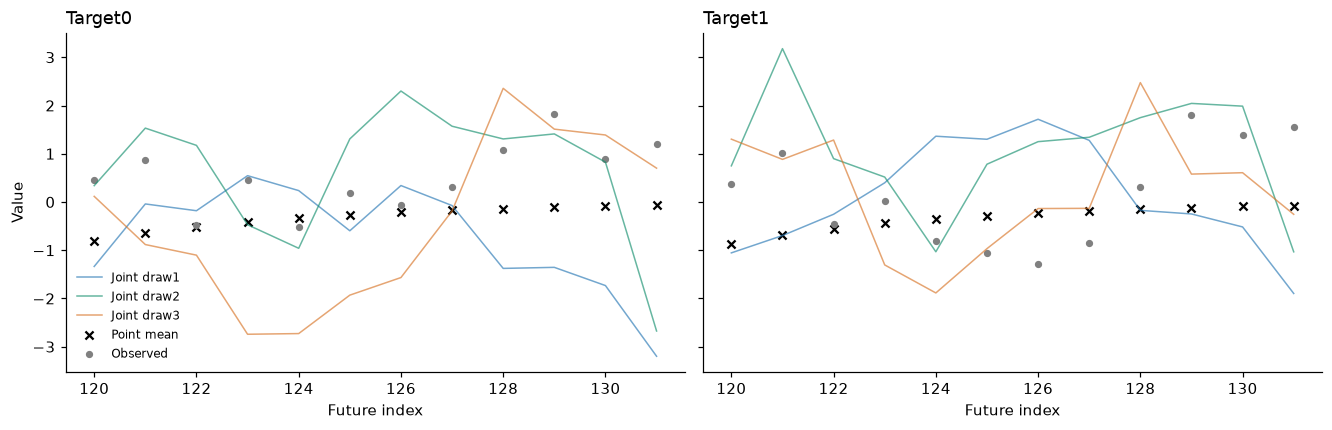

In [11]:
from timegym import Scenario
case = Scenario('ar1', context_length=120, horizon=12, n_targets=2,
                parameters={'phi': .8, 'correlation': .8}).generate(seed=5)
# Scenario belongs to another chapter. Rebuild its inputs with the
# contract classes defined above so this example tests our live edits.
generated_reference = case.reference
case.task = ForecastTask(case.task.context.copy(deep=True), case.task.future_index.copy())
case.reference = Reference(
    mean=generated_reference.mean.copy(), variance=generated_reference.variance.copy(),
    covariance=generated_reference.covariance.copy(), index=generated_reference.index.copy(),
    target_names=generated_reference.target_names,
    conditioning=generated_reference.conditioning.copy(),
)
forecast = case.reference.forecast(n_samples=64, seed=20)
assert ForecastTask.__module__ == Reference.__module__ == Forecast.__module__ == __name__
assert type(case.task) is ForecastTask
assert type(case.reference) is Reference
assert type(forecast) is Forecast
assert forecast.validate(case.task) == []
assert forecast.point.shape == (12, 2)
assert forecast.samples.shape == (64, 12, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout='constrained')
colors = ['#2878b5', '#16906f', '#d87528']
for target, ax in enumerate(axes):
    for sample, color in enumerate(colors):
        ax.plot(forecast.index, forecast.samples[sample, :, target], color=color, alpha=.65,
                lw=1, label=f'Joint draw{sample+1}')
    ax.scatter(forecast.index, forecast.point[:, target], marker='x', color='black', s=28, label='Point mean')
    ax.scatter(case.observed.index, case.observed.iloc[:, target], color='.5', s=14, label='Observed')
    ax.set(title=f'Target{target}', xlabel='Future index')
axes[0].set_ylabel('Value'); axes[0].legend(fontsize=8)
plt.show()

Matching colors identify the same draw across targets. These connected sample paths are distributional simulations; the point forecasts remain crosses. Marginal quantiles alone cannot recover the joint pairing.

## Supply a known mean function

`Reference.from_function` evaluates a truth function once on the requested index. Supply its Gaussian noise covariance explicitly; a mean curve alone does not determine uncertainty. The function and its known parameters belong to the evaluator, never to the fitted model. For real observations without a known law, use `Case(reference=None, ...)`. The [custom-model tutorial](28_custom_model.ipynb) builds a semi-synthetic example from a real-data curve.


In [12]:
future_index = pd.RangeIndex(20, 24)

def truth(index):
    return (2.0 + 0.1 * index.to_numpy(dtype=float))[:, None]

supplied = Reference.from_function(
    truth, future_index, covariance=0.25 * np.eye(len(future_index)),
    conditioning={"truth": "2 + 0.1 * t", "noise": "independent Gaussian, sd=0.5"},
)
np.testing.assert_allclose(supplied.mean[:, 0], [4.0, 4.1, 4.2, 4.3])
assert supplied.forecast(n_samples=32, seed=7).validate() == []
display(pd.DataFrame({"known_mean": supplied.mean[:, 0],
                      "known_variance": supplied.variance[:, 0]}, index=future_index))


,known_mean,known_variance
20,4.0,0.25
21,4.1,0.25
22,4.2,0.25
23,4.3,0.25


## Edit, run, export

After editing a source cell, **restart this kernel and Run All**. This refreshes the local definitions, the development bindings between modules in this chapter, and the nearby examples. Ordinary Run All does not export files.

Changes to code owned by another chapter require saving that source notebook, running `python tools/export_notebooks.py`, and restarting this kernel before importing the updated package. Runtime provenance describes the exported package, not unexported edits.

Try one implementation or parameter change, rerun this chapter, and inspect the figure or assertion. Save the notebook before exporting.